# Linear and Integer Programming for Business Decisions

**What you'll learn**

- The core senior-DS skill this notebook drills: **translating a messy business question
  into decision variables, an objective, and constraints** — done explicitly and slowly for
  three real problem shapes (budget allocation, transportation, staffing).
- The standard LP trick for **diminishing returns**: piecewise-linear approximation of
  concave response curves — plus the demonstration of exactly how it *silently lies* when
  the curve is not concave, and the binary-variable fix.
- **Shadow prices (duals) as money**: the value of one more dollar of budget or one more
  unit of warehouse capacity, extracted from the solver and *verified by re-solving with a
  perturbed constraint* — the finite-difference check that also tells you when the shadow
  price stops being valid.
- Why **MIP is fundamentally harder than LP**, what the LP relaxation and integrality gap
  are, and why "round the LP" is not a substitute for a MIP.
- When **greedy is provably fine** (concave + simple budget) and when it fails badly
  (knapsack-style coupling, fixed costs) — both demonstrated, not asserted.
- **Predict-then-optimize**: feeding demand forecasts into an optimizer, measuring decision
  regret as a function of forecast error by simulation, and why asymmetric costs mean you
  should optimize against a *quantile*, not the point forecast.

**Why it matters in interviews**

- "Allocate a \$10M marketing budget across channels" is a standard case question for
  senior DS / applied scientist roles in marketplaces, fintech, and ops-heavy companies.
  The expected answer is a formulation, not a vibe.
- "Explain shadow prices to a CFO" tests whether you can turn duality into a business
  decision (raise the budget or cut it? expand which warehouse?).
- "Why not just use a greedy heuristic?" separates candidates who know *when* optimization
  machinery earns its complexity from those who reach for it reflexively (or never).
- Forecasting roles increasingly get "your forecast feeds an optimizer — what do you hand
  it?" — the quantile answer here connects directly to
  [../05_time_series/03_ml_forecasting_backtesting.ipynb](../05_time_series/03_ml_forecasting_backtesting.ipynb).

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pulp
from scipy.optimize import minimize
from scipy.stats import norm

rng = np.random.default_rng(42)

plt.rcParams.update({
    "figure.figsize": (8.5, 4.2),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.autolayout": True,
})
pd.set_option("display.precision", 3)

CBC = pulp.PULP_CBC_CMD(msg=0)  # silent CBC solver, reused everywhere


def solve(prob):
    """Solve and *check the status* — see Pitfall 1 for why this assert matters."""
    prob.solve(CBC)
    status = pulp.LpStatus[prob.status]
    assert status == "Optimal", f"solver returned status '{status}', not Optimal"
    return prob

## 1. The skill: variables, objective, constraints

Every optimization case question is answered with the same three-part translation. Do it
in this order, out loud, before writing any code:

1. **Decision variables** — *what do we actually control?* Not "revenue" (an outcome),
   but "dollars spent on search ads", "units shipped from warehouse A to store 3",
   "number of agents starting the 8am shift". Get the units right and note whether the
   decision is continuous (dollars) or inherently integer (people, trucks, open/closed).
2. **Objective** — *one* number to maximize or minimize, in money whenever possible.
   If stakeholders give you two objectives ("maximize revenue AND minimize spend"),
   that's a modeling conversation, not a solver feature: pick one and constrain the
   other, or price them into a single profit expression.
3. **Constraints** — physics (capacity, demand, hours in a day), policy (min brand
   spend, service levels), and definitions (linking variables together). Every constraint
   should be traceable to a sentence a stakeholder said.

If objective and constraints are **linear** in the decision variables, it's an LP:
solvable at enormous scale, with a *certificate* of optimality and prices (duals) for
free. Each integer or either/or requirement moves you into MIP territory — still very
solvable, but qualitatively harder (Section 6). The three case studies below each start
with this translation, done slowly on purpose.

## 2. Case 1 — marketing budget allocation with diminishing returns

**The business problem.** You have a \$10M quarterly budget across five channels. Each
channel's incremental revenue follows a concave (saturating) response curve — the first
million into search works much harder than the fifth. Finance requires minimum spends on
two channels (existing commitments), and each channel has a saturation cap beyond which
the team won't buy inventory.

**The translation.**

- *Decision variables*: $x_c \ge 0$ = spend (in \$M) in channel $c$. Continuous — dollars
  divide.
- *Objective*: maximize $\sum_c f_c(x_c)$, where $f_c$ is channel $c$'s incremental
  revenue curve. We simulate ground truth as $f_c(x) = A_c\,(1 - e^{-x/s_c})$: $A_c$ is
  the channel's total addressable revenue, $s_c$ its saturation scale. (In real life the
  curves come from a media-mix model or geo experiments —
  [../03_causal_inference](../03_causal_inference) territory; the optimization consumes
  them.)
- *Constraints*: $\sum_c x_c \le B$ (budget); $x_c \ge lo_c$ (commitments);
  $x_c \le hi_c$ (saturation caps).

**The catch**: $f_c$ is nonlinear, so this is not an LP as written. The standard trick —
used constantly in practice — is next.

In [2]:
channels = pd.DataFrame(
    {
        # A = addressable incremental revenue ($M), s = saturation scale ($M),
        # lo/hi = min/max spend ($M), hist = last year's spend ($M)
        "A":    [12.0, 7.0, 8.0, 1.8, 3.2],
        "s":    [3.0, 2.0, 4.0, 0.4, 1.8],
        "lo":   [0.5, 0.3, 0.0, 0.1, 0.0],
        "hi":   [6.0, 4.0, 5.0, 0.8, 3.0],
        "hist": [3.0, 2.0, 2.5, 0.5, 2.0],
    },
    index=["search", "social", "video", "email", "display"],
)
BUDGET = 10.0  # $M


def rev_curve(x, A, s):
    """Ground-truth concave response: revenue ($M) from spend x ($M)."""
    return A * (1.0 - np.exp(-np.asarray(x, dtype=float) / s))


def total_true_revenue(alloc):
    return sum(rev_curve(alloc[c], channels.at[c, "A"], channels.at[c, "s"])
               for c in channels.index)


# marginal revenue per $ at spend x: f'(x) = (A/s) * exp(-x/s)
channels["marginal_at_0"] = channels.A / channels.s
print(channels)
print(f"\nTotal budget: ${BUDGET}M; "
      f"sum of last year's spend: ${channels['hist'].sum()}M")

            A    s   lo   hi  hist  marginal_at_0
search   12.0  3.0  0.5  6.0   3.0          4.000
social    7.0  2.0  0.3  4.0   2.0          3.500
video     8.0  4.0  0.0  5.0   2.5          2.000
email     1.8  0.4  0.1  0.8   0.5          4.500
display   3.2  1.8  0.0  3.0   2.0          1.778

Total budget: $10.0M; sum of last year's spend: $10.0M


### 2.1 The piecewise-linear trick

Chop each curve $f_c$ into $K$ segments between breakpoints
$0 = b_0 < b_1 < \dots < b_K = hi_c$. Introduce a variable $z_{c,k} \in [0, w_{c,k}]$
for the spend inside segment $k$ (width $w_{c,k} = b_{k+1} - b_k$), with per-segment
slope $m_{c,k} = \frac{f_c(b_{k+1}) - f_c(b_k)}{w_{c,k}}$. Then

$$x_c = \sum_k z_{c,k}, \qquad f_c(x_c) \approx \sum_k m_{c,k}\, z_{c,k}.$$

**Why this works without any integer variables**: because $f_c$ is *concave*, the slopes
decrease ($m_{c,0} > m_{c,1} > \dots$), and because we are *maximizing*, the LP always
fills cheaper-index segments first — the fill order the approximation assumes. Concavity
+ maximization (equivalently convexity + minimization) is the precondition. When it's
violated the LP silently reports revenue you cannot actually earn — demonstrated in
Pitfall 2.

In [3]:
N_SEG = 8


def segment_data(c, n_seg=N_SEG):
    """Breakpoint widths and slopes for channel c's piecewise approximation."""
    row = channels.loc[c]
    bp = np.linspace(0.0, row.hi, n_seg + 1)
    f = rev_curve(bp, row.A, row.s)
    widths = np.diff(bp)
    slopes = np.diff(f) / widths
    return widths, slopes


def build_marketing_lp(budget):
    """Return (prob, spend_exprs, z) — solutions/exercises can add constraints."""
    prob = pulp.LpProblem("marketing_budget", pulp.LpMaximize)
    z, spend, obj = {}, {}, []
    for c in channels.index:
        widths, slopes = segment_data(c)
        for k in range(N_SEG):
            z[c, k] = pulp.LpVariable(f"z_{c}_{k}", lowBound=0, upBound=widths[k])
            obj.append(slopes[k] * z[c, k])
        spend[c] = pulp.lpSum(z[c, k] for k in range(N_SEG))
    prob += pulp.lpSum(obj)                                     # objective
    prob += (pulp.lpSum(spend.values()) <= budget, "budget")    # budget
    for c in channels.index:                                    # commitments
        prob += (spend[c] >= channels.at[c, "lo"], f"min_{c}")
    # note: x_c <= hi_c is already encoded by the segment upper bounds
    return prob, spend, z


def solve_marketing(budget):
    prob, spend, z = build_marketing_lp(budget)
    solve(prob)
    alloc = pd.Series({c: sum(z[c, k].value() for k in range(N_SEG))
                       for c in channels.index})
    return {
        "alloc": alloc,
        "pw_revenue": pulp.value(prob.objective),      # what the LP *thinks* it earns
        "true_revenue": total_true_revenue(alloc),     # what the curves actually pay
        "budget_pi": prob.constraints["budget"].pi,    # shadow price of budget
    }


opt = solve_marketing(BUDGET)
pro_rata = channels["hist"] / channels["hist"].sum() * BUDGET  # keep last year's mix

report = pd.DataFrame({
    "pro_rata ($M)": pro_rata,
    "optimal ($M)": opt["alloc"],
    "marginal $/$ at pro_rata": channels.A / channels.s * np.exp(-pro_rata / channels.s),
    "marginal $/$ at optimal": channels.A / channels.s * np.exp(-opt["alloc"] / channels.s),
})
print(report)

rev_pro_rata = total_true_revenue(pro_rata)
lift = opt["true_revenue"] - rev_pro_rata
print(f"\nRevenue, pro-rata allocation : ${rev_pro_rata:.3f}M")
print(f"Revenue, LP allocation       : ${opt['true_revenue']:.3f}M "
      f"(LP's own estimate {opt['pw_revenue']:.3f}M — approximation error "
      f"{abs(opt['pw_revenue'] - opt['true_revenue']) * 1e3:.1f}k)")
print(f"Lift from optimizing         : ${lift:.3f}M  (+{lift / rev_pro_rata:.1%}), "
      f"same total spend")

         pro_rata ($M)  optimal ($M)  marginal $/$ at pro_rata  \
search             3.0          3.75                     1.472   
social             2.0          2.40                     1.288   
video              2.5          2.50                     1.071   
email              0.5          0.60                     1.289   
display            2.0          0.75                     0.585   

         marginal $/$ at optimal  
search                     1.146  
social                     1.054  
video                      1.071  
email                      1.004  
display                    1.172  

Revenue, pro-rata allocation : $19.159M
Revenue, LP allocation       : $19.660M (LP's own estimate 19.649M — approximation error 11.1k)
Lift from optimizing         : $0.501M  (+2.6%), same total spend


Read the marginal-rate columns — they *are* the story. Under pro-rata, marginal returns
range widely: some channels earn far more per incremental dollar than others, which means
money is in the wrong place. At the optimum, every channel that isn't pinned at its
min/max cap has (approximately) the **same marginal return** — the *equimarginal
principle*. That equalized rate is exactly the shadow price of the budget (Section 5).
The lift comes purely from reallocating the same \$10M — the cheapest money in marketing.

**Sanity check**: the piecewise LP should land within a hair of the true nonlinear
optimum. Verify against a direct concave solve (SLSQP on the exact curves).

In [4]:
def neg_total_revenue(x):
    return -sum(rev_curve(x[i], channels.A.iloc[i], channels.s.iloc[i])
                for i in range(len(channels)))


res = minimize(
    neg_total_revenue,
    x0=pro_rata.values,
    bounds=list(zip(channels.lo, channels.hi)),
    constraints=[{"type": "ineq", "fun": lambda x: BUDGET - x.sum()}],
    method="SLSQP",
)
assert res.success
exact = pd.Series(res.x, index=channels.index)
print(pd.DataFrame({"piecewise LP": opt["alloc"], "exact concave (SLSQP)": exact}))
print(f"\nTrue revenue: LP alloc ${opt['true_revenue']:.4f}M vs "
      f"exact ${-res.fun:.4f}M -> gap {(-res.fun - opt['true_revenue']) * 1e3:.2f}k "
      f"with only {N_SEG} segments/channel")

         piecewise LP  exact concave (SLSQP)
search           3.75                  3.871
social           2.40                  2.313
video            2.50                  2.390
email            0.60                  0.563
display          0.75                  0.863

True revenue: LP alloc $19.6603M vs exact $19.6725M -> gap 12.22k with only 8 segments/channel


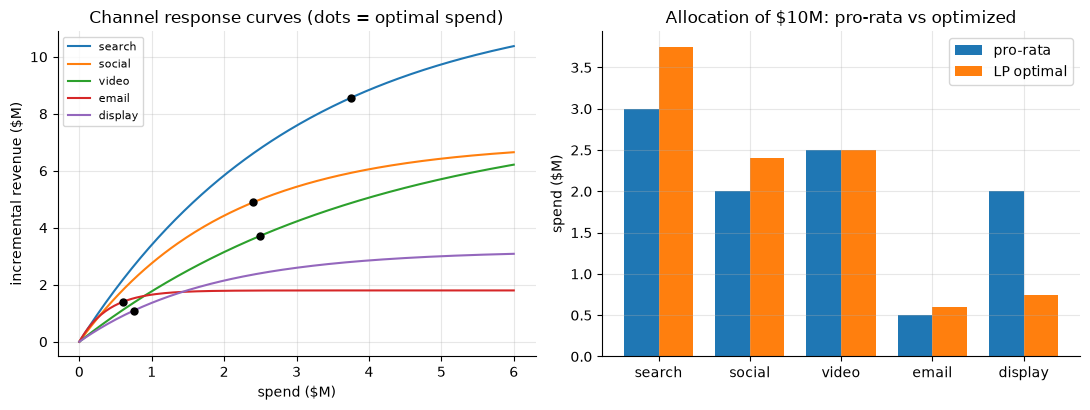

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
xs = np.linspace(0, 6, 200)
for c in channels.index:
    axes[0].plot(xs, rev_curve(xs, channels.at[c, "A"], channels.at[c, "s"]), label=c)
    axes[0].plot(opt["alloc"][c],
                 rev_curve(opt["alloc"][c], channels.at[c, "A"], channels.at[c, "s"]),
                 "ko", ms=5)
axes[0].set(title="Channel response curves (dots = optimal spend)",
            xlabel="spend ($M)", ylabel="incremental revenue ($M)")
axes[0].legend(fontsize=8)

w = 0.38
ix = np.arange(len(channels))
axes[1].bar(ix - w / 2, pro_rata, w, label="pro-rata")
axes[1].bar(ix + w / 2, opt["alloc"], w, label="LP optimal")
axes[1].set(title=f"Allocation of ${BUDGET:.0f}M: pro-rata vs optimized",
            xticks=ix, xticklabels=channels.index, ylabel="spend ($M)")
axes[1].legend()
plt.show()

## 3. Case 2 — transportation: warehouses to stores

**The business problem.** Four warehouses with fixed weekly capacity serve nine stores
with known demand. Shipping cost per unit differs by lane (roughly: distance). Minimize
total shipping cost while meeting every store's demand and respecting capacity.

**The translation.**

- *Decision variables*: $y_{ij} \ge 0$ = units shipped from warehouse $i$ to store $j$.
  One variable per *lane*, not per warehouse — the decision is the flow.
- *Objective*: minimize $\sum_{ij} c_{ij}\, y_{ij}$.
- *Constraints*: $\sum_j y_{ij} \le \mathrm{supply}_i$ (capacity, per warehouse);
  $\sum_i y_{ij} = \mathrm{demand}_j$ (fulfillment, per store).

This is the classic **transportation problem** — a network LP. A fact worth knowing in
interviews: its constraint matrix is *totally unimodular*, so with integer supplies and
demands the LP optimum is automatically integral — you get whole-unit shipments **without
declaring integer variables**. Assignment and shortest-path problems share this property;
it's why "but units are integers!" doesn't automatically make a problem a MIP.

In [6]:
n_wh, n_st = 4, 9
wh_xy = rng.uniform(0, 100, size=(n_wh, 2))
st_xy = rng.uniform(0, 100, size=(n_st, 2))
supply = np.array([280, 320, 250, 300])                     # units/week
demand = rng.integers(80, 150, size=n_st)
demand = np.round(demand * 1000 / demand.sum()).astype(int)  # scale to ~1000 total
dist = np.linalg.norm(wh_xy[:, None, :] - st_xy[None, :, :], axis=2)
cost = 2.0 + 0.08 * dist                                     # $/unit per lane


def build_transport(supply, demand, cost):
    m, n = cost.shape
    prob = pulp.LpProblem("transport", pulp.LpMinimize)
    y = {(i, j): pulp.LpVariable(f"y_{i}_{j}", lowBound=0)
         for i in range(m) for j in range(n)}
    prob += pulp.lpSum(cost[i, j] * y[i, j] for i in range(m) for j in range(n))
    for i in range(m):
        prob += (pulp.lpSum(y[i, j] for j in range(n)) <= supply[i], f"cap_{i}")
    for j in range(n):
        prob += (pulp.lpSum(y[i, j] for i in range(m)) == demand[j], f"dem_{j}")
    return prob, y


prob_t, y = build_transport(supply, demand, cost)
solve(prob_t)
flows = np.array([[y[i, j].value() for j in range(n_st)] for i in range(n_wh)])

flow_df = pd.DataFrame(flows, index=[f"WH{i}" for i in range(n_wh)],
                       columns=[f"S{j}" for j in range(n_st)])
flow_df["shipped"] = flows.sum(axis=1)
flow_df["capacity"] = supply
print(flow_df)
print(f"\nTotal demand {demand.sum()} units; total capacity {supply.sum()} units")
print(f"Optimal shipping cost: ${pulp.value(prob_t.objective):,.0f}/week")
print(f"All flows integral without integer variables: "
      f"{bool(np.allclose(flows, np.round(flows)))}  (total unimodularity)")

        S0     S1     S2    S3     S4    S5     S6    S7     S8  shipped  \
WH0    0.0    0.0    0.0   0.0  115.0   0.0  129.0   0.0   36.0    280.0   
WH1    0.0    0.0    0.0  81.0    0.0  88.0    0.0  47.0  104.0    320.0   
WH2  102.0  109.0    0.0   0.0    0.0   0.0    0.0   0.0    0.0    211.0   
WH3    0.0    0.0  111.0   0.0    0.0   0.0    0.0  77.0    0.0    188.0   

     capacity  
WH0       280  
WH1       320  
WH2       250  
WH3       300  

Total demand 999 units; total capacity 1150 units
Optimal shipping cost: $4,451/week
All flows integral without integer variables: True  (total unimodularity)


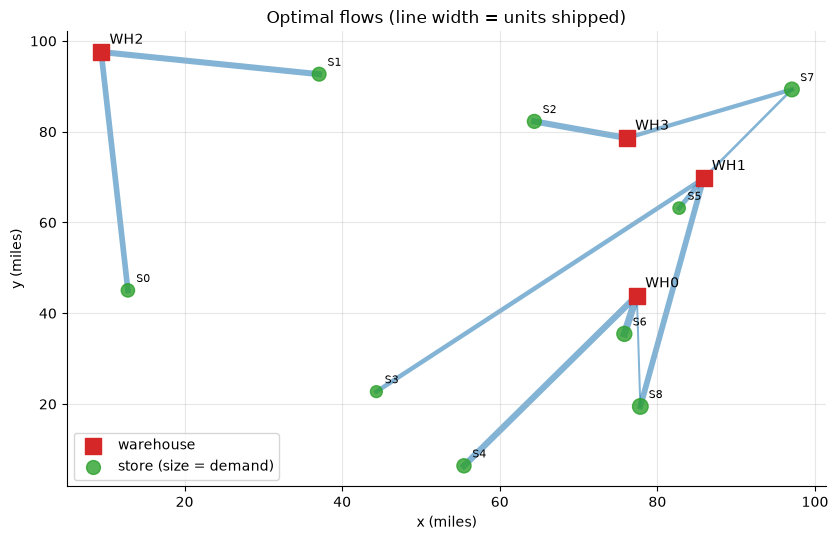

In [7]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
for i in range(n_wh):
    for j in range(n_st):
        if flows[i, j] > 1e-6:
            ax.plot([wh_xy[i, 0], st_xy[j, 0]], [wh_xy[i, 1], st_xy[j, 1]],
                    "-", color="tab:blue", alpha=0.55,
                    lw=0.04 * flows[i, j], zorder=1)
ax.scatter(*wh_xy.T, marker="s", s=140, c="tab:red", zorder=3, label="warehouse")
ax.scatter(*st_xy.T, s=demand * 0.9, c="tab:green", alpha=0.8, zorder=2,
           label="store (size = demand)")
for i in range(n_wh):
    ax.annotate(f"WH{i}", wh_xy[i], textcoords="offset points", xytext=(6, 6))
for j in range(n_st):
    ax.annotate(f"S{j}", st_xy[j], textcoords="offset points", xytext=(6, 6), fontsize=8)
ax.set(title="Optimal flows (line width = units shipped)", xlabel="x (miles)",
       ylabel="y (miles)")
ax.legend(loc="best")
plt.show()

Notice the *structure* of the optimum: most stores are single-sourced from the nearest
non-saturated warehouse, and split sourcing appears only where a capacity constraint
binds. Basic feasible solutions of an LP are extreme points — sparse by nature. That
sparsity is operationally convenient (fewer lanes to manage) and it falls out of the
math for free.

## 4. Case 3 — staffing a call center: our first true MIP

**The business problem.** Hourly demand for agents over a 24-hour day is known (from a
forecast — Section 7 makes that link honest). Agents work a standard contact-center
roster: **8 paid hours spread over a 9-hour window, with an unpaid lunch hour in the
middle** (the 5th hour — the agent is off the phones). Shifts can start at any hour;
hours between 22:00 and 06:00 pay a 1.5x night premium. Staff every hour at or above
demand, at minimum wage cost.

**The translation.**

- *Decision variables*: $n_s \in \{0, 1, 2, \dots\}$ = number of agents starting shift
  $s$. **Integer** — you cannot hire 0.4 of a person. This single modeling fact changes
  the problem class.
- *Objective*: minimize $\sum_s c_s n_s$ where $c_s$ = wage cost of one agent on shift
  $s$ (8 paid hours, night hours at 1.5x).
- *Constraints*: for every hour $h$: $\sum_{s \ni h} n_s \ge d_h$ — total agents *on the
  phones* during hour $h$ must meet demand. (Cyclic: a shift starting at 22:00 wraps
  past midnight; the lunch hour does not count as coverage.)

We represent a shift generically as `(start, coverage_offsets, pay_multiplier)` — that
flexibility pays off in Exercise 3 when part-time shifts join the mix.

In [8]:
hourly_demand = np.array([4, 3, 3, 3, 4, 6, 9, 14, 18, 21, 22, 21,
                          19, 18, 17, 18, 20, 21, 18, 14, 11, 8, 6, 5])
WAGE = 28.0                      # $/hour base
NIGHT = {22, 23, 0, 1, 2, 3, 4, 5}
LUNCH_8H = (0, 1, 2, 3, 5, 6, 7, 8)     # paid/covering offsets; hour 4 = unpaid lunch
FULL_TIME = [(h, LUNCH_8H, 1.0) for h in range(24)]  # (start, offsets, pay multiplier)


def shift_cost(start, offsets, mult):
    return sum(WAGE * mult * (1.5 if (start + o) % 24 in NIGHT else 1.0)
               for o in offsets)


def build_staffing(demand, shifts=FULL_TIME, integer=True):
    prob = pulp.LpProblem("staffing", pulp.LpMinimize)
    cat = "Integer" if integer else "Continuous"
    n = {s: pulp.LpVariable(f"n_{s[0]}_{len(s[1])}_{s[2]}", lowBound=0, cat=cat)
         for s in shifts}
    prob += pulp.lpSum(shift_cost(*s) * n[s] for s in shifts)
    covers = {h: [s for s in shifts if h in {(s[0] + o) % 24 for o in s[1]}]
              for h in range(24)}
    for h in range(24):
        prob += (pulp.lpSum(n[s] for s in covers[h]) >= demand[h], f"cover_{h}")
    return prob, n, covers


def staff_solution(demand, shifts=FULL_TIME, integer=True):
    prob, n, covers = build_staffing(demand, shifts, integer)
    solve(prob)
    coverage = np.array([sum(n[s].value() for s in covers[h]) for h in range(24)])
    return {"cost": pulp.value(prob.objective), "coverage": coverage,
            "n": {s: n[s].value() for s in shifts if n[s].value() > 1e-6}}


mip = staff_solution(hourly_demand)
print(f"MIP optimal daily wage cost: ${mip['cost']:,.0f}")
print(f"Agents hired: {sum(mip['n'].values()):.0f}")
print("Shifts used (start hour -> agents):",
      {s[0]: int(v) for s, v in sorted(mip["n"].items())})

MIP optimal daily wage cost: $9,996
Agents hired: 42
Shifts used (start hour -> agents): {2: 3, 3: 2, 5: 1, 6: 6, 7: 4, 8: 2, 9: 4, 10: 6, 12: 3, 13: 3, 14: 2, 16: 3, 17: 3}


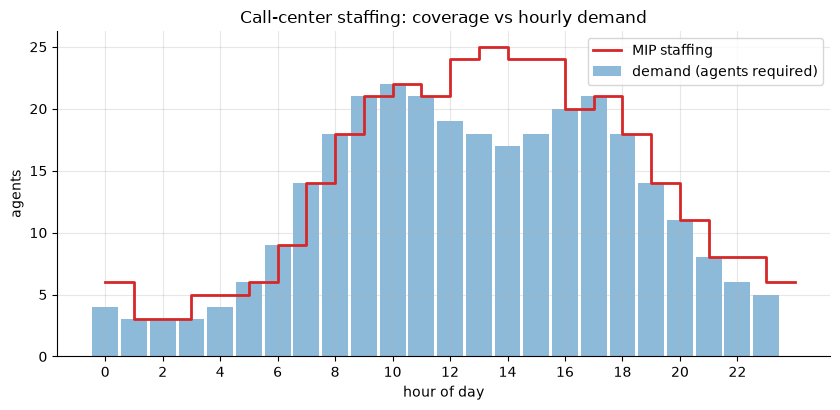

Overstaffed agent-hours: 33 (unavoidable — rigid shift shapes cannot trace a spiky demand curve exactly)


In [9]:
fig, ax = plt.subplots()
hours = np.arange(24)
ax.bar(hours, hourly_demand, width=0.9, alpha=0.5, label="demand (agents required)")
ax.step(np.append(hours, 24), np.append(mip["coverage"], mip["coverage"][-1]),
        where="post", color="tab:red", lw=2, label="MIP staffing")
ax.set(title="Call-center staffing: coverage vs hourly demand",
       xlabel="hour of day", ylabel="agents", xticks=range(0, 24, 2))
ax.legend()
plt.show()
over = mip["coverage"] - hourly_demand
print(f"Overstaffed agent-hours: {over.sum():.0f} "
      f"(unavoidable — rigid shift shapes cannot trace a spiky demand curve exactly)")

### 4.1 Why you can't just round the LP relaxation

Drop the integrality requirement and you get the **LP relaxation** — same objective and
constraints, fractional agents allowed. Its optimum is a *lower bound* on the MIP cost
(more freedom can only help). The two standard "shortcuts" both fail:

- **Round down** → hours go under-covered (infeasible).
- **Round up** → feasible but costs more than the true MIP optimum.

The gap between LP-relaxation cost and MIP cost is the **integrality gap** — the price
of people coming in whole units, and the quantity branch-and-bound spends its life
closing.

In [10]:
lp_relax = staff_solution(hourly_demand, integer=False)
frac = {s: v for s, v in lp_relax["n"].items() if abs(v - round(v)) > 1e-6}
print(f"LP relaxation cost: ${lp_relax['cost']:,.0f}  "
      f"(MIP: ${mip['cost']:,.0f}; integrality gap "
      f"{(mip['cost'] - lp_relax['cost']) / mip['cost']:.2%})")
print(f"Fractional shift counts in LP solution: "
      f"{ {s[0]: round(v, 2) for s, v in sorted(frac.items())} }")

# round DOWN: check feasibility
prob_lp, n_lp, covers = build_staffing(hourly_demand, integer=False)
solve(prob_lp)
down = {s: np.floor(n_lp[s].value()) for s in n_lp}
cov_down = np.array([sum(down[s] for s in covers[h]) for h in range(24)])
viol = (cov_down < hourly_demand).sum()
up = {s: np.ceil(n_lp[s].value()) for s in n_lp}
cost_up = sum(shift_cost(*s) * v for s, v in up.items())
print(f"Round down -> {viol} of 24 hours under-staffed (INFEASIBLE)")
print(f"Round up   -> feasible but ${cost_up:,.0f} "
      f"(${cost_up - mip['cost']:,.0f} above MIP optimum)")

# Structure decides whether integrality is free. Remove the lunch break so every shift
# covers 8 CONSECUTIVE hours (a 'circular ones' constraint matrix) and the LP relaxation
# happens to come back integral — no MIP needed, like the transportation problem:
straight = staff_solution(hourly_demand,
                          shifts=[(h, tuple(range(8)), 1.0) for h in range(24)],
                          integer=False)
n_frac = sum(abs(v - round(v)) > 1e-6 for v in straight["n"].values())
print(f"\nSame LP with consecutive-hour shifts (no lunch): fractional variables = "
      f"{n_frac}.\nThe lunch break destroys the consecutive-ones structure — and with "
      f"it, free integrality.\nSmall modeling details decide problem class; check "
      f"before assuming you need a MIP (or don't).")

LP relaxation cost: $9,977  (MIP: $9,996; integrality gap 0.19%)
Fractional shift counts in LP solution: {1: 0.89, 2: 1.22, 3: 1.89, 5: 2.89, 6: 3.33, 7: 5.67, 8: 2.11, 9: 5.89, 10: 2.33, 11: 2.56, 12: 4.22, 13: 2.33, 14: 0.33, 16: 2.44, 17: 1.22, 18: 0.89}
Round down -> 19 of 24 hours under-staffed (INFEASIBLE)
Round up   -> feasible but $11,858 ($1,862 above MIP optimum)

Same LP with consecutive-hour shifts (no lunch): fractional variables = 0.
The lunch break destroys the consecutive-ones structure — and with it, free integrality.
Small modeling details decide problem class; check before assuming you need a MIP (or don't).


### 4.2 Why MIP is genuinely harder

- An LP's feasible region is a convex polytope: any local optimum is global, the simplex
  or interior-point method finds it in (practical) polynomial time, and duality hands you
  a proof of optimality.
- A MIP's feasible set is a *lattice of disconnected integer points* — not convex. There
  is no local-search guarantee, and MIP is NP-hard: branch-and-bound solves a *tree* of
  LP relaxations, using each relaxation as a bound to prune. Worst case exponential;
  in practice modern solvers (CBC here; Gurobi/CPLEX/HiGHS commercially) handle
  $10^5$–$10^6$ binaries *when the formulation is tight* — i.e., when the LP relaxation
  hugs the integer hull. Formulation quality, not raw size, is what kills MIPs
  (loose big-M constants are the classic offender).
- Practical consequence for you: an LP re-solve is cheap enough to embed in a loop or a
  what-if dashboard; a hard MIP may need warm starts, time limits, and an accepted
  optimality gap ("stop at 0.5%"). Say this in interviews — it signals production
  experience.

## 5. Duality for practitioners: shadow prices are money

Every LP constraint has a **dual value** ("shadow price"): the rate of change of the
optimal objective per unit relaxation of that constraint's right-hand side. For a
business audience:

> *The shadow price of the budget is what the next dollar of budget would earn. The
> shadow price of warehouse capacity is what one more unit of capacity would save.*

Rules a senior candidate should state:

- Non-binding constraint (slack > 0) → shadow price **zero**. More of a thing you're not
  fully using is worth nothing.
- Shadow prices are **local**: valid only until the binding pattern changes. Never
  extrapolate far (Pitfall 3 quantifies this).
- Solver sign conventions differ. **Trust but verify**: re-solve with the RHS perturbed
  and take the finite difference. That check costs one solve and has saved many analyses.

In [11]:
# --- Budget shadow price in Case 1: extract, then verify by perturbation ---
pi = opt["budget_pi"]
eps = 0.1  # +$100k of budget
opt_eps = solve_marketing(BUDGET + eps)
fd = (opt_eps["pw_revenue"] - opt["pw_revenue"]) / eps
print(f"Solver dual on budget constraint : {pi:.4f}  ($ revenue per $ budget)")
print(f"Finite-difference check (+$100k) : {fd:.4f}")
print(f"\nInterpretation: at a ${BUDGET:.0f}M budget, the next marketing dollar returns "
      f"~${pi:.2f} of revenue.")
print("It also equals the equimarginal rate of the unconstrained channels "
      "(compare the 'marginal at optimal' column in Section 2).")

Solver dual on budget constraint : 1.1392  ($ revenue per $ budget)
Finite-difference check (+$100k) : 1.1392

Interpretation: at a $10M budget, the next marketing dollar returns ~$1.14 of revenue.
It also equals the equimarginal rate of the unconstrained channels (compare the 'marginal at optimal' column in Section 2).


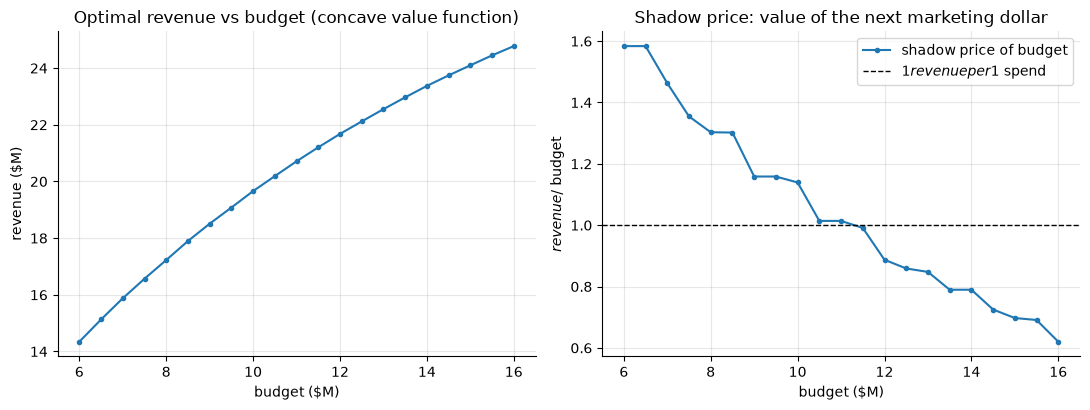

The shadow price falls below $1/$1 at ~$11.5M — beyond that, an incremental marketing dollar returns less than a dollar of revenue.
That is the CFO-ready answer to 'should the budget be bigger?': grow it while the shadow price beats your hurdle rate, stop when it doesn't.


In [12]:
# --- Sensitivity what-if: sweep the budget, watch the shadow price decay ---
budgets = np.arange(6.0, 16.01, 0.5)
sweep = pd.DataFrame(
    [{"budget": b, **{k: v for k, v in solve_marketing(b).items() if k != "alloc"}}
     for b in budgets]
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(sweep.budget, sweep.true_revenue, "-o", ms=3)
axes[0].set(title="Optimal revenue vs budget (concave value function)",
            xlabel="budget ($M)", ylabel="revenue ($M)")
axes[1].plot(sweep.budget, sweep.budget_pi, "-o", ms=3, label="shadow price of budget")
axes[1].axhline(1.0, color="k", ls="--", lw=1, label="$1 revenue per $1 spend")
axes[1].set(title="Shadow price: value of the next marketing dollar",
            xlabel="budget ($M)", ylabel="$ revenue / $ budget")
axes[1].legend()
plt.show()

cross = sweep.loc[sweep.budget_pi < 1.0, "budget"].min()
print(f"The shadow price falls below $1/$1 at ~${cross:.1f}M — beyond that, an "
      f"incremental marketing dollar returns less than a dollar of revenue.")
print("That is the CFO-ready answer to 'should the budget be bigger?': "
      "grow it while the shadow price beats your hurdle rate, stop when it doesn't.")

In [13]:
# --- Capacity shadow prices in Case 2: which warehouse deserves expansion? ---
cap_rows = []
for i in range(n_wh):
    con = prob_t.constraints[f"cap_{i}"]
    cap_rows.append({"warehouse": f"WH{i}", "capacity": supply[i],
                     "shipped": flows[i].sum(), "slack": con.slack,
                     "savings_per_extra_unit": -con.pi})  # min problem: pi <= 0
cap_df = pd.DataFrame(cap_rows).set_index("warehouse")
print(cap_df)

best = cap_df.savings_per_extra_unit.idxmax()
i_best = int(best[-1])
supply2 = supply.copy()
supply2[i_best] += 10
prob_p, _ = build_transport(supply2, demand, cost)
solve(prob_p)
saved = pulp.value(prob_t.objective) - pulp.value(prob_p.objective)
print(f"\n{best} has the highest capacity value "
      f"(${cap_df.loc[best, 'savings_per_extra_unit']:.2f}/unit).")
print(f"Verification: +10 units at {best} saves ${saved:.2f} vs predicted "
      f"${10 * cap_df.loc[best, 'savings_per_extra_unit']:.2f}.")
print("Warehouses with slack capacity have shadow price ~0: expanding them is worthless.")
print("\nPer-store duals = marginal cost to serve one more unit at that store "
      "(useful for pricing/margin analysis):")
print(pd.Series({f"S{j}": prob_t.constraints[f"dem_{j}"].pi for j in range(n_st)},
                name="$ per extra unit demanded"))

           capacity  shipped  slack  savings_per_extra_unit
warehouse                                                  
WH0             280    280.0   -0.0                   2.196
WH1             320    320.0   -0.0                   0.078
WH2             250    211.0   39.0                  -0.000
WH3             300    188.0  112.0                  -0.000

WH0 has the highest capacity value ($2.20/unit).
Verification: +10 units at WH0 saves $21.96 vs predicted $21.96.
Warehouses with slack capacity have shadow price ~0: expanding them is worthless.

Per-store duals = marginal cost to serve one more unit at that store (useful for pricing/margin analysis):
S0    6.211
S1    4.247
S2    2.983
S3    7.096
S4    7.672
S5    2.659
S6    4.883
S7    3.883
S8    6.151
Name: $ per extra unit demanded, dtype: float64


In [14]:
# --- Warning: MIP constraints do NOT have meaningful shadow prices ---
tight_hours = [h for h in range(24) if mip["coverage"][h] == hourly_demand[h]]
h_t = max(tight_hours, key=lambda h: hourly_demand[h])  # a binding peak hour
prob_m, n_m, _ = build_staffing(hourly_demand)
solve(prob_m)
print(f"Hour {h_t}:00 is binding (coverage == demand == {hourly_demand[h_t]}).")
print(f"Dual CBC reports on that MIP constraint: "
      f"{prob_m.constraints[f'cover_{h_t}'].pi}")
d2 = hourly_demand.copy()
d2[h_t] += 1
fd_mip = staff_solution(d2)["cost"] - mip["cost"]
print(f"True marginal cost of +1 agent required at {h_t}:00 (by re-solving): "
      f"${fd_mip:.0f}")
print("Duality is an LP concept. For MIPs, get sensitivities the honest way: "
      "perturb and re-solve.")

Hour 10:00 is binding (coverage == demand == 22).
Dual CBC reports on that MIP constraint: 0.0
True marginal cost of +1 agent required at 10:00 (by re-solving): $126
Duality is an LP concept. For MIPs, get sensitivities the honest way: perturb and re-solve.


## 6. LP vs MIP tractability — and when greedy is fine

**LPs scale.** Millions of variables are routine for good solvers; the model below shows
even open-source CBC dispatching mid-sized transportation LPs instantly (and that with
PuLP, Python model-*building* time can dominate solver time — a real production
consideration; at scale you generate models with matrix APIs, not Python loops).

In [15]:
def time_transport(m, n):
    s = rng.integers(50, 150, m)
    d = rng.integers(10, 40, n)
    d = np.round(d * (0.8 * s.sum() / d.sum())).astype(int)
    c = rng.uniform(1, 10, size=(m, n))
    t0 = time.perf_counter()
    prob, _ = build_transport(s, d, c)
    t1 = time.perf_counter()
    solve(prob)
    t2 = time.perf_counter()
    return {"warehouses": m, "stores": n, "variables": m * n,
            "build_s": t1 - t0, "solve_s": t2 - t1}


print(pd.DataFrame([time_transport(m, n)
                    for m, n in [(10, 20), (30, 60), (60, 120)]]))

   warehouses  stores  variables  build_s  solve_s
0          10      20        200    0.004    0.010
1          30      60       1800    0.020    0.027
2          60     120       7200    0.181    0.091


### 6.1 Greedy is *provably fine* for concave budget allocation...

For Case 1's structure — separable concave returns, one budget constraint — the greedy
algorithm "repeatedly put the next dollar where the marginal return is highest" is
optimal (it's the polymatroid/fractional-knapsack case; greedy on the sorted piecewise
segments is exactly what the simplex method ends up doing). So *if that's your whole
problem*, a 10-line greedy is a legitimate answer, and saying so in an interview shows
judgment.

In [16]:
def greedy_alloc(budget):
    alloc = channels.lo.astype(float).copy()  # honor the minimums first
    pool = []
    for c in channels.index:
        widths, slopes = segment_data(c)
        to_fill = alloc[c]  # minimum spend occupies the earliest segments
        for k in range(N_SEG):
            used = min(widths[k], to_fill)
            to_fill -= used
            if widths[k] - used > 1e-12:
                pool.append((slopes[k], c, widths[k] - used))
    left = budget - alloc.sum()
    for slope, c, capacity in sorted(pool, reverse=True):  # best marginal rate first
        take = min(capacity, left)
        alloc[c] += take
        left -= take
        if left <= 1e-12:
            break
    return alloc


greedy = greedy_alloc(BUDGET)
print(f"Greedy revenue: ${total_true_revenue(greedy):.4f}M   "
      f"LP revenue: ${opt['true_revenue']:.4f}M   "
      f"difference: ${abs(total_true_revenue(greedy) - opt['true_revenue']) * 1e6:,.0f}")

Greedy revenue: $19.6603M   LP revenue: $19.6603M   difference: $0


### 6.2 ...and greedy fails hard the moment decisions get lumpy

Add *indivisibility* — projects you fund entirely or not at all — and the same
"best ratio first" instinct breaks. The classic counterexample is a knapsack:

In [17]:
projects = pd.DataFrame({
    "value": [60, 100, 120],          # $k payoff
    "budget_needed": [10, 20, 30],    # $k, all-or-nothing
}, index=["proj_A", "proj_B", "proj_C"])
projects["ratio"] = projects.value / projects.budget_needed
CAP = 50

# greedy by value/cost ratio
left, g_val, picked = CAP, 0, []
for name, row in projects.sort_values("ratio", ascending=False).iterrows():
    if row.budget_needed <= left:
        left -= row.budget_needed
        g_val += row.value
        picked.append(name)

# exact MIP
kp = pulp.LpProblem("knapsack", pulp.LpMaximize)
pick = {p: pulp.LpVariable(f"pick_{p}", cat="Binary") for p in projects.index}
kp += pulp.lpSum(projects.at[p, "value"] * pick[p] for p in projects.index)
kp += pulp.lpSum(projects.at[p, "budget_needed"] * pick[p]
                 for p in projects.index) <= CAP
solve(kp)
m_val = pulp.value(kp.objective)
m_picked = [p for p in projects.index if pick[p].value() > 0.5]

print(projects)
print(f"\nGreedy picks {picked}: value ${g_val}k")
print(f"MIP    picks {m_picked}: value ${m_val:.0f}k  "
      f"-> greedy left {(m_val - g_val) / m_val:.0%} of the value on the table")

        value  budget_needed  ratio
proj_A     60             10    6.0
proj_B    100             20    5.0
proj_C    120             30    4.0

Greedy picks ['proj_A', 'proj_B']: value $160.0k
MIP    picks ['proj_B', 'proj_C']: value $220k  -> greedy left 27% of the value on the table


Greedy grabbed the best *ratio* (`proj_A`) and thereby blocked the best *combination*.
The general rule:

| structure | greedy? | why |
|---|---|---|
| separable concave returns, single budget | **optimal** | equimarginal principle; fractional filling allowed |
| + integrality / all-or-nothing costs | fails | combinatorial packing (knapsack) |
| + fixed activation costs or min-viable spends | fails | non-convex; also breaks plain LP (Pitfall 2's binaries fix it) |
| + coupling constraints (joint caps, precedence) | fails | local choices constrain each other |

**Convexity is the deeper point.** An LP (or any convex program) is trustworthy because
*local optimality implies global optimality*, and strong duality supplies a
**certificate**: when primal and dual objectives meet, the solver has *proved* nothing
better exists. Heuristics give you a number; LP gives you a number plus a proof plus
prices. That trifecta is the honest answer to "why bother with the machinery?"

## 7. Predict-then-optimize: feeding forecasts into the optimizer

Real staffing models don't receive `hourly_demand` on stone tablets — they receive a
*forecast*, built exactly like
[../05_time_series/03_ml_forecasting_backtesting.ipynb](../05_time_series/03_ml_forecasting_backtesting.ipynb).
The pipeline is **predict → optimize → realize**: staff against the forecast, then pay
real costs against *true* demand:

- covered hours cost wages (already in the objective);
- **under**-staffed agent-hours cost far more — on a revenue-bearing queue, an
  agent-hour of shortage means abandoned calls, lost sales, and SLA penalty credits.
  We price it at \$500/agent-hour vs ~\$28–42 for an idle agent-hour: an
  order-of-magnitude asymmetry, not unusual for sales or retention queues.

Two questions a senior candidate should answer with a simulation, not an opinion:
(1) how fast does decision quality degrade with forecast error?
(2) given *asymmetric* costs, is the point forecast even the right thing to optimize
against?

In [18]:
SHORTAGE_COST = 500.0  # $ per agent-hour understaffed


def staff_and_realize(forecast, true_demand, buffer=1.0):
    """Optimize against buffer*forecast, then pay real costs against true demand.

    The agent requirement fed to the MIP is np.ceil(...): you need a whole agent to
    cover 17.3 agents of load (the conservative operational convention). A pleasant
    side effect: an integer right-hand side keeps CBC's branch-and-bound almost
    trivial, ~100x faster per solve than fractional requirements — worth knowing
    when you embed a MIP inside a simulation loop.
    """
    sol = staff_solution(np.ceil(np.asarray(forecast, dtype=float) * buffer))
    shortage_hours = np.maximum(true_demand - sol["coverage"], 0).sum()
    return sol["cost"] + SHORTAGE_COST * shortage_hours


oracle_cost = staff_and_realize(hourly_demand, hourly_demand)  # perfect foresight
print(f"Oracle (perfect forecast) realized cost: ${oracle_cost:,.0f}/day")

sigmas, n_sims = [0.05, 0.15, 0.25], 100
records = []
for sigma in sigmas:
    for _ in range(n_sims):
        forecast = hourly_demand * np.exp(rng.normal(0, sigma, size=24))
        cost_r = staff_and_realize(forecast, hourly_demand)
        records.append({"forecast_error_sigma": sigma,
                        "regret": cost_r - oracle_cost})
regret = pd.DataFrame(records)
print("\nDecision regret ($/day) vs forecast error (multiplicative sigma):")
print(regret.groupby("forecast_error_sigma").regret.describe()[["mean", "50%", "max"]])

Oracle (perfect forecast) realized cost: $9,996/day



Decision regret ($/day) vs forecast error (multiplicative sigma):
                         mean     50%      max
forecast_error_sigma                          
0.05                   987.02   920.0   2458.0
0.15                  3490.94  3281.0   7084.0
0.25                  5288.12  4845.0  11972.0


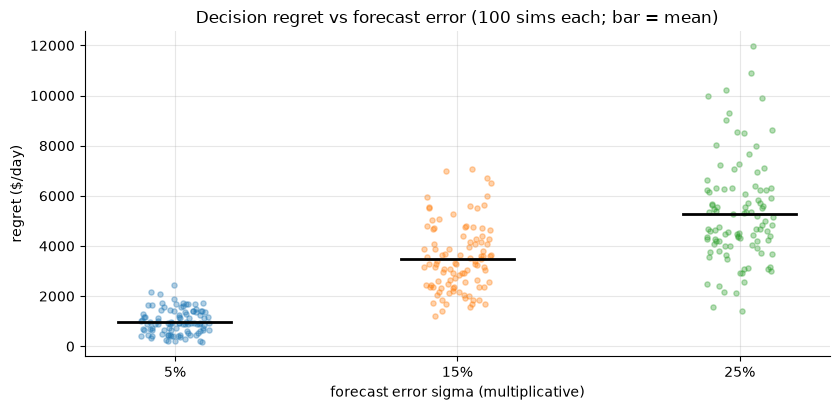

Regret grows much faster than linearly in forecast error — and it is one-sided risk:
under-forecasting the peak is what hurts, because shortage costs dwarf idle-agent costs.


In [19]:
fig, ax = plt.subplots()
for i, sigma in enumerate(sigmas):
    vals = regret.loc[regret.forecast_error_sigma == sigma, "regret"]
    ax.scatter(np.full(len(vals), i) + rng.uniform(-0.12, 0.12, len(vals)),
               vals, alpha=0.35, s=14)
    ax.plot([i - 0.2, i + 0.2], [vals.mean()] * 2, "k-", lw=2)
ax.set(title=f"Decision regret vs forecast error ({n_sims} sims each; bar = mean)",
       xticks=range(len(sigmas)), xticklabels=[f"{s:.0%}" for s in sigmas],
       xlabel="forecast error sigma (multiplicative)", ylabel="regret ($/day)")
plt.show()
print("Regret grows much faster than linearly in forecast error — and it is one-sided "
      "risk:\nunder-forecasting the peak is what hurts, because shortage costs dwarf "
      "idle-agent costs.")

### 7.1 Asymmetric costs → optimize against a quantile, not the mean

This is the **newsvendor logic**: with underage cost $c_u$ (shortage: \$500) and
overage cost $c_o$ (idle agent: ~\$31 blended), the service point should be the demand
quantile at the *critical fractile* $\frac{c_u}{c_u + c_o} \approx 0.94$ — about
$z \approx 1.6$ sigmas above the point forecast, **if** the raw newsvendor model
applied cleanly. It doesn't quite: the MIP already over-covers some hours (shift shapes
are rigid), which acts as a *built-in* buffer. So treat the fractile as the direction
and ceiling, and let **simulation** find the residual buffer: staff to
`forecast * exp(z * sigma)` (the lognormal P-quantile at $z$ sigmas) and measure
realized cost. Same forecasts reused across all $z$ (paired design) so the comparison
is clean.

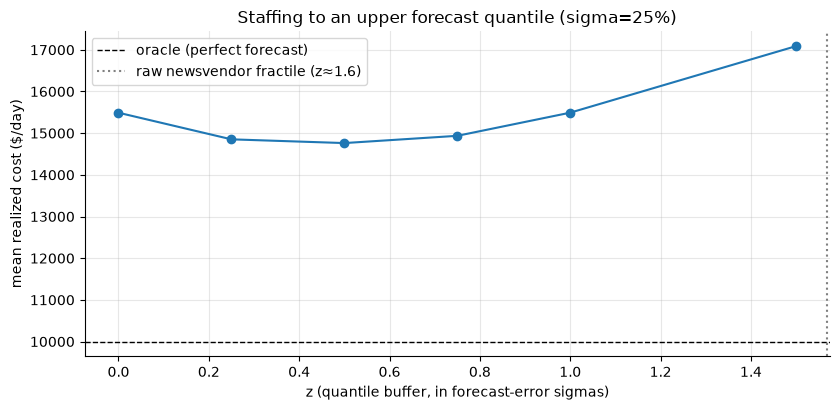

Best buffer tested: z=0.50 (~P69 forecast), saving $728/day vs staffing to the point forecast (z=0).
Two lessons: (1) under asymmetric costs the point forecast is the wrong input — staff to an
upper quantile; (2) the best buffer sits BELOW the textbook fractile because the shift
structure already over-covers some hours. Simulate the pipeline; don't just plug in formulas.
This is why the forecasting notebook builds P10/P50/P90 — downstream decisions consume quantiles.


In [20]:
sigma_fixed = 0.25
zs = [0.0, 0.25, 0.5, 0.75, 1.0, 1.5]
n_paired = 200
forecasts = [hourly_demand * np.exp(rng.normal(0, sigma_fixed, size=24))
             for _ in range(n_paired)]
buf_records = []
for z in zs:
    for f in forecasts:
        cost_r = staff_and_realize(f, hourly_demand, buffer=np.exp(z * sigma_fixed))
        buf_records.append({"z": z, "realized": cost_r})
buf = pd.DataFrame(buf_records).groupby("z").realized.mean()

fig, ax = plt.subplots()
ax.plot(buf.index, buf.values, "-o")
ax.axhline(oracle_cost, color="k", ls="--", lw=1, label="oracle (perfect forecast)")
ax.axvline(norm.ppf(SHORTAGE_COST / (SHORTAGE_COST + 31)), color="gray", ls=":",
           label="raw newsvendor fractile (z≈1.6)")
ax.set(title=f"Staffing to an upper forecast quantile (sigma={sigma_fixed:.0%})",
       xlabel="z (quantile buffer, in forecast-error sigmas)",
       ylabel="mean realized cost ($/day)")
ax.legend()
plt.show()
print(f"Best buffer tested: z={buf.idxmin():.2f} "
      f"(~P{100 * norm.cdf(buf.idxmin()):.0f} forecast), "
      f"saving ${buf[0.0] - buf.min():,.0f}/day vs staffing to the point forecast "
      f"(z=0).")
print("Two lessons: (1) under asymmetric costs the point forecast is the wrong input — "
      "staff to an\nupper quantile; (2) the best buffer sits BELOW the textbook "
      "fractile because the shift\nstructure already over-covers some hours. Simulate "
      "the pipeline; don't just plug in formulas.")
print("This is why the forecasting notebook builds P10/P50/P90 — downstream decisions "
      "consume quantiles.")

Two closing notes on predict-then-optimize, worth naming in interviews:

- **Evaluate forecasts in decision units.** A model with slightly worse MAPE but better
  peak-hour quantile calibration can be *cheaper to operate*. Backtest the whole
  predict→optimize pipeline (regret in dollars), not the forecast in isolation.
- **Decision-focused learning** ("smart predict-then-optimize", SPO+) trains the
  forecaster directly on downstream decision loss. Worth mentioning; in practice the
  quantile trick above captures most of the value at a fraction of the complexity.

## 8. Pitfalls

### Pitfall 1 — not checking solver status

PuLP happily leaves variable values populated after a failed solve. If you skip the
status check, an infeasible model hands you a garbage "answer" that flows straight into
a business deck.

In [21]:
bad = pulp.LpProblem("impossible", pulp.LpMaximize)
xs_bad = {c: pulp.LpVariable(f"xb_{c}", lowBound=channels.at[c, "lo"])
          for c in channels.index}
bad += pulp.lpSum(xs_bad.values())
bad += pulp.lpSum(xs_bad.values()) <= 0.5   # budget below the sum of minimum spends!
bad.solve(CBC)                              # note: NOT our solve() wrapper

print(f"Status: {pulp.LpStatus[bad.status]}")
print(f"'Objective' PuLP reports anyway: {pulp.value(bad.objective)}")
print(f"'Allocation' you could naively read off: "
      f"{ {c: v.value() for c, v in xs_bad.items()} }")
print("\nAlways gate on LpStatus == 'Optimal' (our solve() helper asserts it). "
      "'Infeasible' and\n'Unbounded' are diagnoses: infeasible -> conflicting "
      "constraints (find them by softening\nconstraints with penalty slacks); "
      "unbounded -> a missing constraint or sign error.")

Status: Infeasible
'Objective' PuLP reports anyway: 0.9
'Allocation' you could naively read off: {'search': 0.5, 'social': 0.3, 'video': 0.0, 'email': 0.1, 'display': 0.0}

Always gate on LpStatus == 'Optimal' (our solve() helper asserts it). 'Infeasible' and
'Unbounded' are diagnoses: infeasible -> conflicting constraints (find them by softening
constraints with penalty slacks); unbounded -> a missing constraint or sign error.


### Pitfall 2 — the piecewise trick *requires* concavity

Give the LP an S-shaped response curve (slow start, steep middle — common for channels
with awareness thresholds) and the segment slopes are no longer decreasing. The LP
fills the *steepest* (middle) segments first without paying for the flat early part —
reporting revenue the curve cannot actually deliver at that spend.

In [22]:
A_s, m_s, t_s = 5.0, 2.5, 0.7


def s_curve(x):
    x = np.asarray(x, dtype=float)
    g = 1 / (1 + np.exp(-(x - m_s) / t_s))
    g0 = 1 / (1 + np.exp(m_s / t_s))
    return A_s * (g - g0) / (1 - g0)


K = 10
bp = np.linspace(0, 5, K + 1)
w_seg = np.diff(bp)
m_seg = np.diff(s_curve(bp)) / w_seg
BUD_S = 2.0

naive = pulp.LpProblem("scurve_naive", pulp.LpMaximize)
zn = [pulp.LpVariable(f"zn_{k}", 0, w_seg[k]) for k in range(K)]
naive += pulp.lpSum(m_seg[k] * zn[k] for k in range(K))
naive += pulp.lpSum(zn) <= BUD_S
solve(naive)

spend_n = sum(v.value() for v in zn)
print(f"Segment slopes (should be decreasing for the trick to work):\n"
      f"{np.round(m_seg, 2)}")
print(f"\nNaive LP: spend ${spend_n:.2f}M, claimed revenue "
      f"${pulp.value(naive.objective):.2f}M")
print(f"TRUE revenue at ${spend_n:.2f}M spend: ${s_curve(spend_n):.2f}M "
      f"-> the LP overstates by "
      f"{pulp.value(naive.objective) / s_curve(spend_n) - 1:.0%}")
print(f"Filled segments (out of order!): "
      f"{[k for k in range(K) if zn[k].value() > 1e-6]}")

Segment slopes (should be decreasing for the trick to work):
[0.28 0.52 0.91 1.39 1.76 1.76 1.39 0.91 0.52 0.28]

Naive LP: spend $2.00M, claimed revenue $3.15M
TRUE revenue at $2.00M spend: $1.55M -> the LP overstates by 104%
Filled segments (out of order!): [3, 4, 5, 6]


In [23]:
# The fix: ordering binaries force segments to fill left-to-right (a small MIP).
fixed = pulp.LpProblem("scurve_fixed", pulp.LpMaximize)
zf = [pulp.LpVariable(f"zf_{k}", 0, w_seg[k]) for k in range(K)]
yf = [pulp.LpVariable(f"yf_{k}", cat="Binary") for k in range(K)]
fixed += pulp.lpSum(m_seg[k] * zf[k] for k in range(K))
fixed += pulp.lpSum(zf) <= BUD_S
for k in range(K):
    fixed += zf[k] <= w_seg[k] * yf[k]           # can't use segment k unless opened
    if k + 1 < K:
        fixed += zf[k] >= w_seg[k] * yf[k + 1]   # must FILL k before opening k+1
        fixed += yf[k + 1] <= yf[k]
solve(fixed)
spend_f = sum(v.value() for v in zf)
print(f"MIP with ordering binaries: spend ${spend_f:.2f}M, claimed revenue "
      f"${pulp.value(fixed.objective):.2f}M vs true ${s_curve(spend_f):.2f}M — honest.")
print("(General non-convex piecewise curves use the same idea via SOS2 constraints. "
      "The lesson:\ncheck slope monotonicity before trusting the LP trick — one line "
      "of numpy.)")

MIP with ordering binaries: spend $2.00M, claimed revenue $1.55M vs true $1.55M — honest.
(General non-convex piecewise curves use the same idea via SOS2 constraints. The lesson:
check slope monotonicity before trusting the LP trick — one line of numpy.)


### Pitfall 3 — extrapolating a shadow price outside its validity range

A shadow price is a *derivative at the current optimum*. It holds only while the set of
binding constraints doesn't change — here, roughly one piecewise segment of budget. Use
it to price small changes; re-solve for big ones.

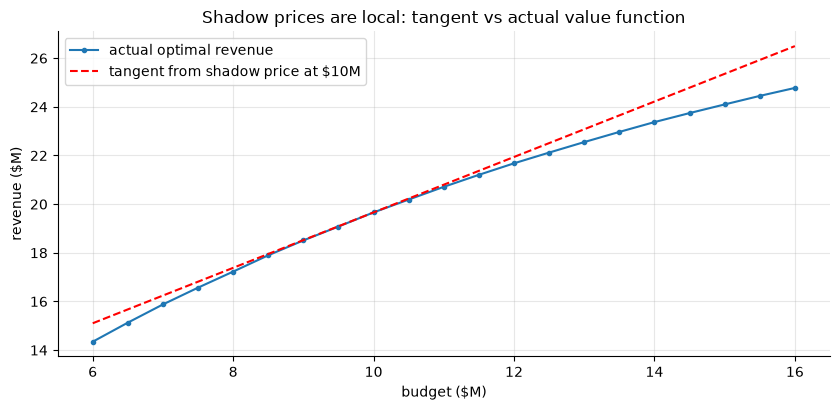

Shadow-price extrapolation to $15M predicts $25.36M revenue; actual optimum is $24.10M
-> over-promise of $1,258k. Commercial solvers report ranging information (the RHS interval
where the dual stays valid); with open-source stacks, just re-solve — LPs are cheap.

Other traps to keep on the checklist: unit mismatches between objective and constraints;
loose big-M constants (weak relaxations, numeric trouble); equality constraints on floats;
and modeling outcomes you don't control as decision variables.


In [24]:
b0 = BUDGET
row0 = sweep.loc[np.isclose(sweep.budget, b0)].iloc[0]
tangent = row0.true_revenue + row0.budget_pi * (sweep.budget - b0)

fig, ax = plt.subplots()
ax.plot(sweep.budget, sweep.true_revenue, "-o", ms=3, label="actual optimal revenue")
ax.plot(sweep.budget, tangent, "r--",
        label=f"tangent from shadow price at ${b0:.0f}M")
ax.set(title="Shadow prices are local: tangent vs actual value function",
       xlabel="budget ($M)", ylabel="revenue ($M)")
ax.legend()
plt.show()

big = 15.0
pred = row0.true_revenue + row0.budget_pi * (big - b0)
act = sweep.loc[np.isclose(sweep.budget, big), "true_revenue"].iloc[0]
print(f"Shadow-price extrapolation to ${big:.0f}M predicts ${pred:.2f}M revenue; "
      f"actual optimum is ${act:.2f}M\n-> over-promise of "
      f"${(pred - act) * 1000:,.0f}k. Commercial solvers report ranging information "
      f"(the RHS interval\nwhere the dual stays valid); with open-source stacks, "
      f"just re-solve — LPs are cheap.")
print("\nOther traps to keep on the checklist: unit mismatches between objective and "
      "constraints;\nloose big-M constants (weak relaxations, numeric trouble); "
      "equality constraints on floats;\nand modeling outcomes you don't control as "
      "decision variables.")

## 9. Interview corner

**Q1. "You have \$10M to allocate across marketing channels. Walk me through it."**
Strong answer: (1) clarify the objective (incremental revenue? profit? CAC-constrained
growth?) and the horizon; (2) name the input you actually need — *causal* channel
response curves, from MMM or geo experiments, not last-click attribution; (3) state that
curves saturate, so this is concave maximization → piecewise-linearize and solve as an
LP with budget/min/max constraints; (4) report the equimarginal solution ("spend until
marginal ROI equalizes"), the lift vs current allocation, and the budget's shadow price
as the case for more/less budget; (5) note uncertainty in the curves and validate with
holdout experiments before full rollout. Bonus: mention that with fixed activation costs
or channel synergies it becomes a MIP / nonlinear problem.

**Q2. "Explain shadow prices to a CFO."**
"The shadow price of a constraint is what the next unit of that resource is worth: one
more budget dollar returns \$1.14; one more unit of WH0 capacity saves \$2.20/week.
Resources we're not fully using are worth \$0 more at the margin. The numbers are local —
they hold for the next increment, not for doubling — and I verify each by re-running the
plan with the constraint relaxed." Then *use* it: rank capacity investments, set the
budget where shadow price = hurdle rate. No mention of dual variables required.

**Q3. "When is greedy fine, and when does it fail?"**
Greedy = optimal for separable concave returns under a single budget (equimarginal
logic; fractional knapsack). It fails with (a) all-or-nothing decisions — knapsack
counterexample where the best ratio blocks the best combination; (b) fixed/activation
costs (non-convexity); (c) coupling constraints. Even when greedy is near-optimal, LP
adds duals (prices) and an optimality certificate. Senior move: say you'd *start* with
greedy as a baseline and bound, then justify heavier machinery by the gap.

**Q4. "What changes when your LP becomes a MIP?"**
Integrality (people, trucks), logical conditions (either/or, if-then), fixed charges,
min lot sizes → binary/integer variables → NP-hard. Practically: branch-and-bound over
LP relaxations; solve time driven by formulation tightness (big-M discipline), not just
size; expect to manage time limits and accept an optimality gap; duals are no longer
meaningful — sensitivity by re-solving.

**Q5. "The solver says infeasible. What do you do?"**
Never ship the values it leaves behind (status check first). Then: (1) look for unit
errors — the most common cause; (2) soften constraints with penalized slack variables
and see which ones the solver violates — that localizes the conflict; (3) commercial
solvers compute an IIS (irreducible infeasible subsystem) directly; (4) if genuinely
infeasible, the model is telling you the business asks are incompatible — that finding
*is* the deliverable.

**Q6. "Your demand forecast feeds this optimizer. What do you hand it?"**
Not the point forecast — the decision-relevant *quantile*. With asymmetric costs the
newsvendor fractile $c_u/(c_u+c_o)$ sets the service quantile; simulate the whole
predict→optimize pipeline and report *regret in dollars*, not MAPE. Mention
decision-focused learning (SPO+) as the research-grade version, and re-optimizing as
forecasts refresh.

**Q7. "Why should I trust the LP's answer?"**
Convexity: any local optimum is global, and strong duality provides a certificate — when
primal and dual objectives meet, optimality is *proved*, not hoped. What still needs
auditing is the *model*: units, constraints traced to real business statements, shadow
prices passing a smell test, and the recommended decision backtested against the status
quo.

## 10. Key takeaways

- Optimization case questions are answered by a three-part translation — decision
  variables (what you control), objective (one number, in money), constraints (each
  traceable to a stakeholder sentence). Do it out loud before any code.
- Diminishing returns → piecewise-linear LP, but the trick is only valid for concave
  curves under maximization; check slope monotonicity or pay for ordering binaries.
- The optimizer's edge over pro-rata allocation is the equimarginal principle: move
  money until marginal returns equalize. The equalized rate *is* the budget's shadow
  price.
- Shadow prices turn a plan into prices: value of the next budget dollar, next unit of
  capacity, cost to serve each store. Verify them by perturb-and-re-solve; never
  extrapolate them far.
- Transportation/assignment LPs return integer solutions for free (total
  unimodularity); "quantities are integers" does not automatically mean MIP.
- True integrality (people, shifts) does: LP relaxations bound MIPs, rounding them is
  infeasible or suboptimal, and MIP duals are meaningless.
- LPs scale to millions of variables with proofs of optimality; MIP difficulty is
  governed by formulation tightness more than size.
- Greedy is optimal exactly when the problem is concave and un-coupled; lumpy costs and
  packing constraints break it — know the knapsack counterexample cold.
- Predict-then-optimize: measure forecasts by decision regret, and under asymmetric
  costs optimize against the newsvendor quantile, not the point forecast.

## 11. Exercises

**Exercise 1.** Finance imposes a governance cap: digital channels (search + social +
display) may take at most 55% of the \$10M budget. Re-solve Case 1 with this joint
constraint. How does the allocation shift, what revenue does the cap cost, and what is
the cap's shadow price (verify it by perturbation)?

**Exercise 2.** Warehouse WH1 goes offline for a week (supply 0). Re-solve Case 2 and
check the solver status — what is the model telling you? Then handle the outage
properly with an *elastic* formulation: allow unmet demand at a \$25/unit lost-sales
penalty. Which stores get shorted, what does the outage cost in total, and what happens
to the surviving warehouses' capacity shadow prices?

**Exercise 3.** The call center can also hire 4-hour part-time shifts (any start hour)
at a 1.25x hourly premium. Extend Case 3's MIP. How much does the optimal cost drop,
and what happens to overstaffed agent-hours?

In [25]:
# --- Solution 1 ---
DIGITAL = ["search", "social", "display"]
prob_e1, spend_e1, z_e1 = build_marketing_lp(BUDGET)
prob_e1 += (pulp.lpSum(spend_e1[c] for c in DIGITAL) <= 0.55 * BUDGET, "digital_cap")
solve(prob_e1)
alloc_e1 = pd.Series({c: sum(z_e1[c, k].value() for k in range(N_SEG))
                      for c in channels.index})
rev_e1 = total_true_revenue(alloc_e1)
pi_cap = prob_e1.constraints["digital_cap"].pi

print(pd.DataFrame({"unconstrained": opt["alloc"], "with 55% digital cap": alloc_e1}))
print(f"\nDigital share: {alloc_e1[DIGITAL].sum() / BUDGET:.0%} (cap binds)")
print(f"Revenue cost of the cap: ${(opt['true_revenue'] - rev_e1) * 1000:,.0f}k")
print(f"Shadow price of the cap: {pi_cap:.3f} $ revenue per $ of digital allowance")

prob_e1b, spend_e1b, z_e1b = build_marketing_lp(BUDGET)
prob_e1b += (pulp.lpSum(spend_e1b[c] for c in DIGITAL) <= 0.55 * BUDGET + 0.1,
             "digital_cap")
solve(prob_e1b)
fd_cap = (pulp.value(prob_e1b.objective) - pulp.value(prob_e1.objective)) / 0.1
print(f"Perturbation check (+$100k of digital allowance): {fd_cap:.3f} — matches.")
print("Note the money the cap displaces flows to the best NON-digital margin (video), "
      "so the cap\ncosts less than the digital marginal rate alone would suggest.")

         unconstrained  with 55% digital cap
search            3.75                   3.0
social            2.40                   2.0
video             2.50                   3.8
email             0.60                   0.7
display           0.75                   0.5

Digital share: 55% (cap binds)
Revenue cost of the cap: $481k
Shadow price of the cap: 0.578 $ revenue per $ of digital allowance
Perturbation check (+$100k of digital allowance): 0.517 — matches.
Note the money the cap displaces flows to the best NON-digital margin (video), so the cap
costs less than the digital marginal rate alone would suggest.


In [26]:
# --- Solution 2 ---
supply_out = supply.copy()
supply_out[1] = 0
prob_e2, _ = build_transport(supply_out, demand, cost)
prob_e2.solve(CBC)  # deliberately NOT solve(): we expect trouble
print(f"Naive re-solve status: '{pulp.LpStatus[prob_e2.status]}' — remaining capacity "
      f"{supply_out.sum()} < demand {demand.sum()}.")
print("The model is telling us the asks are incompatible. The professional move is an "
      "ELASTIC model\nthat prices the shortfall instead of hiding it:")

LOST_SALE = 25.0  # $ margin lost per unshipped unit
el = pulp.LpProblem("transport_elastic", pulp.LpMinimize)
ye = {(i, j): pulp.LpVariable(f"ye_{i}_{j}", lowBound=0)
      for i in range(n_wh) for j in range(n_st)}
short = {j: pulp.LpVariable(f"short_{j}", lowBound=0) for j in range(n_st)}
el += (pulp.lpSum(cost[i, j] * ye[i, j] for i in range(n_wh) for j in range(n_st))
       + LOST_SALE * pulp.lpSum(short.values()))
for i in range(n_wh):
    el += (pulp.lpSum(ye[i, j] for j in range(n_st)) <= supply_out[i], f"cap_{i}")
for j in range(n_st):
    el += (pulp.lpSum(ye[i, j] for i in range(n_wh)) + short[j] == demand[j],
           f"dem_{j}")
solve(el)

shorted = pd.Series({f"S{j}": short[j].value() for j in range(n_st)})
penalty = LOST_SALE * shorted.sum()
print(f"\nUnits shorted: {shorted.sum():.0f} of {demand.sum()}, at stores "
      f"{ {k: int(v) for k, v in shorted.items() if v > 1e-6} }")
print("(the optimizer sheds demand exactly where serving it is most expensive)")
print(f"Outage week cost: ${pulp.value(el.objective):,.0f} "
      f"(${pulp.value(el.objective) - penalty:,.0f} shipping + ${penalty:,.0f} lost "
      f"sales)\nvs ${pulp.value(prob_t.objective):,.0f} in a normal week")
caps_e2 = pd.Series({f"WH{i}": -el.constraints[f"cap_{i}"].pi
                     for i in range(n_wh) if supply_out[i] > 0},
                    name="capacity value $/unit during outage")
print(f"\n{caps_e2}")
print("Every surviving warehouse is saturated, so capacity that was nearly worthless "
      "last week now\nsaves close to the lost-sale margin per unit — shadow prices are "
      "regime-dependent, which is\nexactly why we re-solve rather than reuse last "
      "week's duals.")

Naive re-solve status: 'Infeasible' — remaining capacity 830 < demand 999.
The model is telling us the asks are incompatible. The professional move is an ELASTIC model
that prices the shortfall instead of hiding it:

Units shorted: 169 of 999, at stores {'S3': 54, 'S4': 115}
(the optimizer sheds demand exactly where serving it is most expensive)
Outage week cost: $7,605 ($3,380 shipping + $4,225 lost sales)
vs $4,451 in a normal week

WH0    19.860
WH2    16.393
WH3    19.974
Name: capacity value $/unit during outage, dtype: float64
Every surviving warehouse is saturated, so capacity that was nearly worthless last week now
saves close to the lost-sale margin per unit — shadow prices are regime-dependent, which is
exactly why we re-solve rather than reuse last week's duals.


In [27]:
# --- Solution 3 ---
PART_TIME = [(h, (0, 1, 2, 3), 1.25) for h in range(24)]  # 4h, no lunch, 1.25x pay
mixed = staff_solution(hourly_demand, shifts=FULL_TIME + PART_TIME)
over_ft = (mip["coverage"] - hourly_demand).sum()
over_mx = (mixed["coverage"] - hourly_demand).sum()

print(f"Full-time only : ${mip['cost']:,.0f}/day, overstaffed agent-hours {over_ft:.0f}")
print(f"With part-time : ${mixed['cost']:,.0f}/day, overstaffed agent-hours "
      f"{over_mx:.0f}")
print(f"Savings: ${mip['cost'] - mixed['cost']:,.0f}/day "
      f"({1 - mixed['cost'] / mip['cost']:.1%})")
pt_used = {s[0]: int(v) for s, v in sorted(mixed["n"].items()) if len(s[1]) == 4}
print(f"Part-time shifts used (start hour -> count): {pt_used}")
print("\nShort shifts trace the demand peaks that 8-hour blocks overshoot — the 25% "
      "hourly premium\nis cheaper than paying full shifts to idle. This flexibility-vs-"
      "premium trade-off is the\nstandard workforce-planning tension, and the MIP prices "
      "it exactly.")

Full-time only : $9,996/day, overstaffed agent-hours 33
With part-time : $9,366/day, overstaffed agent-hours 5
Savings: $630/day (6.3%)
Part-time shifts used (start hour -> count): {7: 5, 8: 2, 15: 1, 16: 1}

Short shifts trace the demand peaks that 8-hour blocks overshoot — the 25% hourly premium
is cheaper than paying full shifts to idle. This flexibility-vs-premium trade-off is the
standard workforce-planning tension, and the MIP prices it exactly.
